# 1.0 EDA inicial: viajes de MiBici (Equipo 49)

**Proyecto:** TC5061, Construye | Proyecto MiBici, Etapa 1.
**Periodo:** octubre de 2025 a septiembre de 2026 (12 meses del portal de datos abiertos).

Este notebook solo muestra **agregados** (conteos por día, hora, estación y chequeos de factibilidad).
No contiene datos a nivel de viaje ni de usuario.

Los CSV crudos no se versionan (`data/` está en `.gitignore`). Las tablas y figuras se generaron con el script
del EDA en la carpeta de investigación y se copiaron a `reports/`. La ingesta reproducible vivirá en `dataset.py`
(paso 10 de la actividad).

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from mibici_ml.config import END_MONTH, FIGURES_DIR, START_MONTH, TABLES_DIR

resumen = json.loads((TABLES_DIR / "resumen.json").read_text(encoding="utf-8"))
print(f"Periodo: {START_MONTH} a {END_MONTH}")
print(f"Viajes en 12 meses (antes de limpieza): {resumen['viajes_12_meses']:,}")
print(f"Estaciones en el catálogo de sep-2026: {resumen['estaciones_catalogo']}")
print(f"IDs de origen con al menos una salida (incluye IDs fuera de catálogo): {resumen['estaciones_con_salidas_12m']}")
print(f"Estaciones del catálogo sin ningún viaje en 12 meses: {resumen['estaciones_sin_viajes_12m']}")

Periodo: 2025-10 a 2026-09
Viajes en 12 meses (antes de limpieza): 4,497,877
Estaciones en el catálogo de sep-2026: 484
IDs de origen con al menos una salida (incluye IDs fuera de catálogo): 471
Estaciones del catálogo sin ningún viaje en 12 meses: 15


## 1. Viajes por mes y calidad de los archivos

Los 12 archivos coinciden en tamaño con lo que reporta el servidor. Enero de 2026 (`2026_01`) está en
cp1252; los demás están en UTF-8. La lectura detecta la codificación de cada archivo.

In [2]:
inventario = pd.read_csv(TABLES_DIR / "inventario_meses.csv", dtype={"mes": str})
columnas = [
    "mes",
    "viajes",
    "encoding",
    "duracion_menor_igual_0_min",
    "origen_igual_destino",
    "genero_NULL_o_vacio",
]
inventario[columnas]

,mes,viajes,encoding,duracion_menor_igual_0_min,origen_igual_destino,genero_NULL_o_vacio
0,2025_10,420064,utf-8,225,23004,4343
1,2025_11,380328,utf-8,214,21025,3894
2,2025_12,335420,utf-8,318,18691,2791
3,2026_01,357180,cp1252,262,20321,2616
4,2026_02,333756,utf-8,1863,24222,2400
5,2026_03,376243,utf-8,215,22385,2470
6,2026_04,351851,utf-8,162,21364,2203
7,2026_05,315895,utf-8,76,22407,1704
8,2026_06,355303,utf-8,116,28896,2283
9,2026_07,388257,utf-8,82,29653,2651


## 2. Volumen diario y perfil horario

Picos alrededor de las 08:00 y las 18:00. Casi no hay viajes entre las 02:00 y las 04:59.

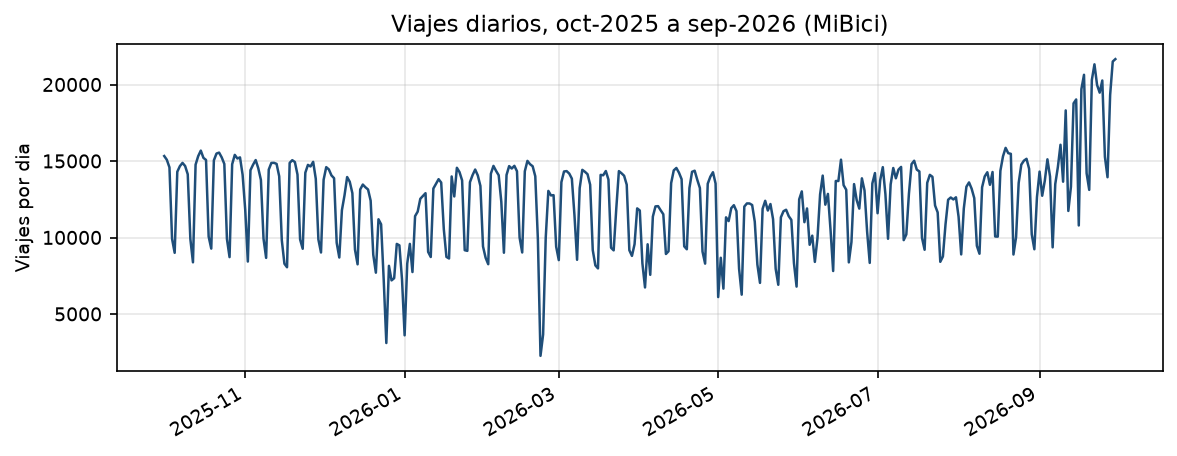

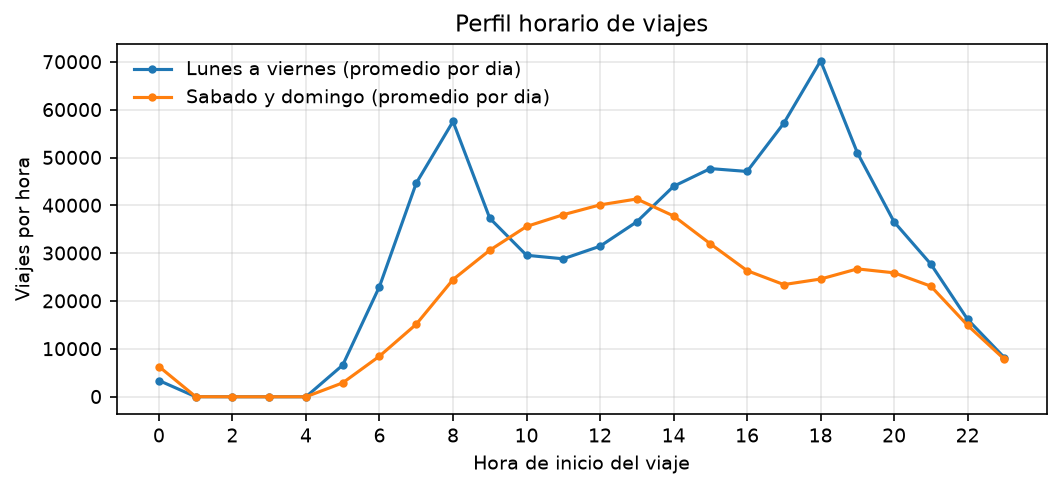

In [3]:
display(Image(filename=str(FIGURES_DIR / "volumen_diario.png"), width=900))
display(Image(filename=str(FIGURES_DIR / "perfil_horario.png"), width=900))

## 3. Día de la semana y hora

El miércoles es el día con más viajes y el domingo el de menos.

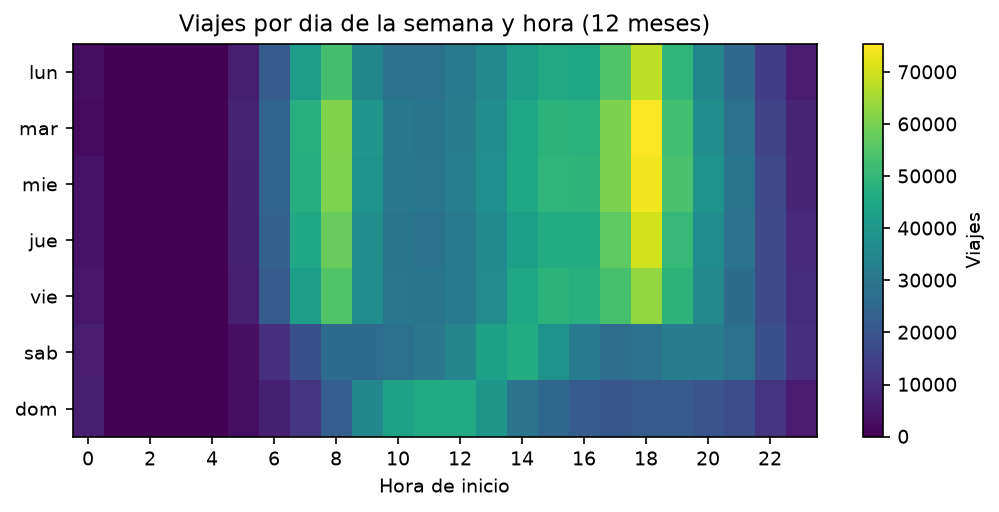

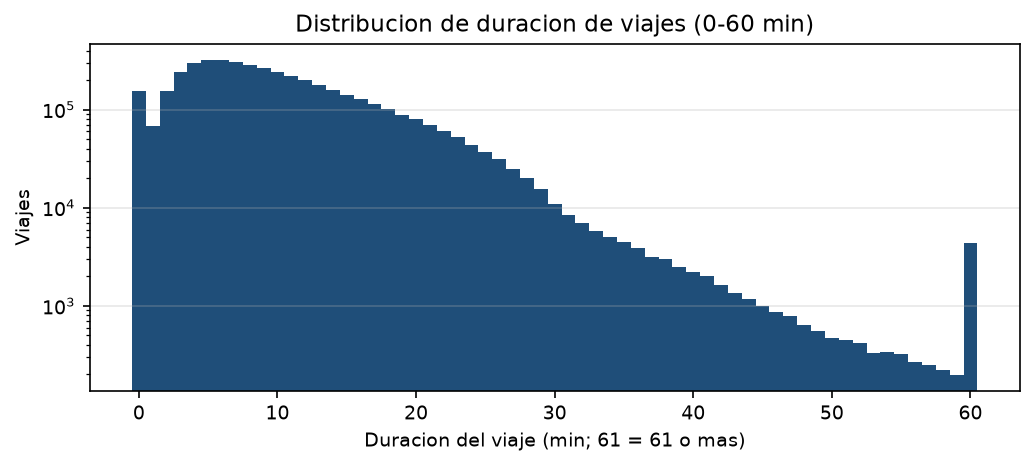

In [4]:
display(Image(filename=str(FIGURES_DIR / "heatmap_dia_hora.png"), width=900))
display(Image(filename=str(FIGURES_DIR / "duracion_viajes.png"), width=900))

## 4. Estaciones

La concentración es alta: el 10% de las estaciones con más salidas acumula el 35.7% de las salidas.
La mediana de salidas por estación en 12 meses es 5,877.

In [5]:
estaciones = pd.read_csv(TABLES_DIR / "estaciones_resumen.csv")
top = estaciones.sort_values("salidas_12m", ascending=False).head(10)
top[["nombre", "capacidad", "salidas_12m", "llegadas_12m"]]

,nombre,capacidad,salidas_12m,llegadas_12m
0,(GDL-049) Lopez Cotilla / Penitenciaría,39,96651,111790
1,(GDL-033) Av. Hidalgo / C. Pedro Loza,15,74406,86849
2,(GDL-198) Av. Alcalde / C. Hospital,31,69628,61044
3,(GDL-009) Calz. Federalismo/ C. J. Angulo,23,64015,58577
4,(GDL-048) C. Constancio Hernández/ Av. Juaréz,23,54015,55177
5,(GDL-127) Av. Vallarta / Av. de Los Arcos,19,52597,25456
6,(GDL-050) C.Pedro Moreno /Federalismo,23,51787,49513
7,(GDL-052) Av. Juarez /16 de Septiembre,23,50209,52323
8,(GDL-036) C. Marcos Castellanos/ C. Morelos,23,40757,41314
9,(GDL-187) Av. 16 de Septiembre / C. Priscilia,15,39163,46519


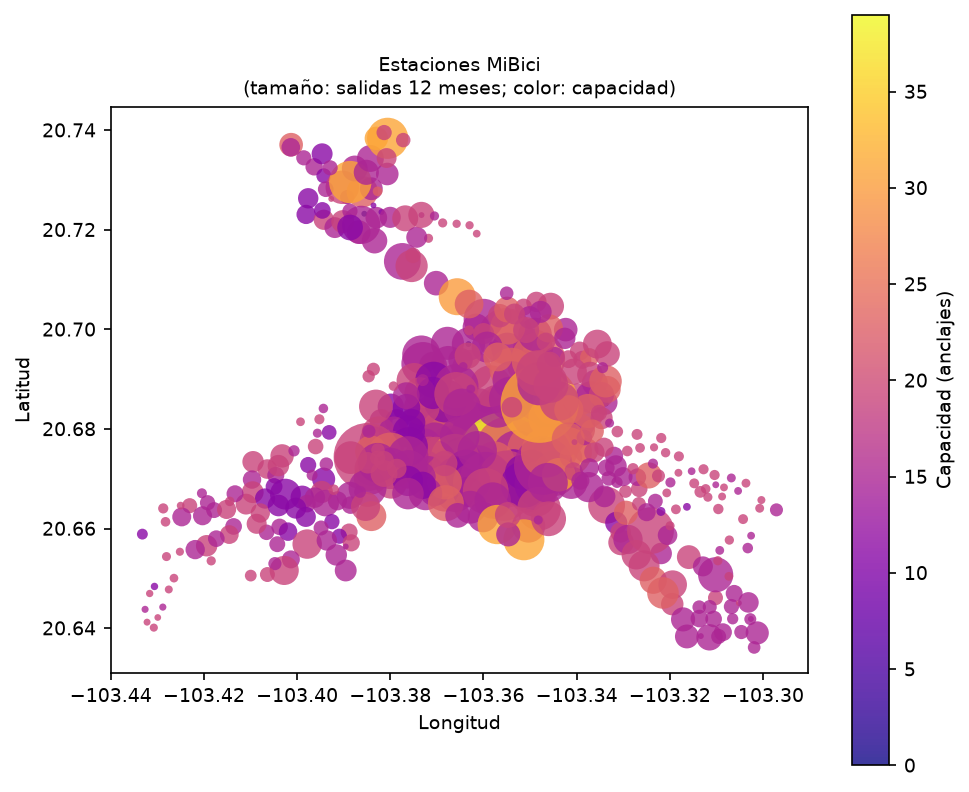

In [6]:
display(Image(filename=str(FIGURES_DIR / "mapa_estaciones.png"), width=900))

## 5. Chequeo de factibilidad para P2

Para cada estación-día se calcula el flujo neto acumulado `F(t)` (llegadas menos salidas) y se verifica si
existe un inventario inicial que mantenga el inventario entre 0 y la capacidad `C`. Esa condición equivale a
`max F - min F <= C`.

In [7]:
factibilidad = pd.read_csv(TABLES_DIR / "factibilidad_p2_por_capacidad.csv")
factibilidad

,capacidad,estacion_dia,pct_factibles
0,11-20,124763,91.11
1,21-30,14731,91.05
2,31-39,2912,82.35


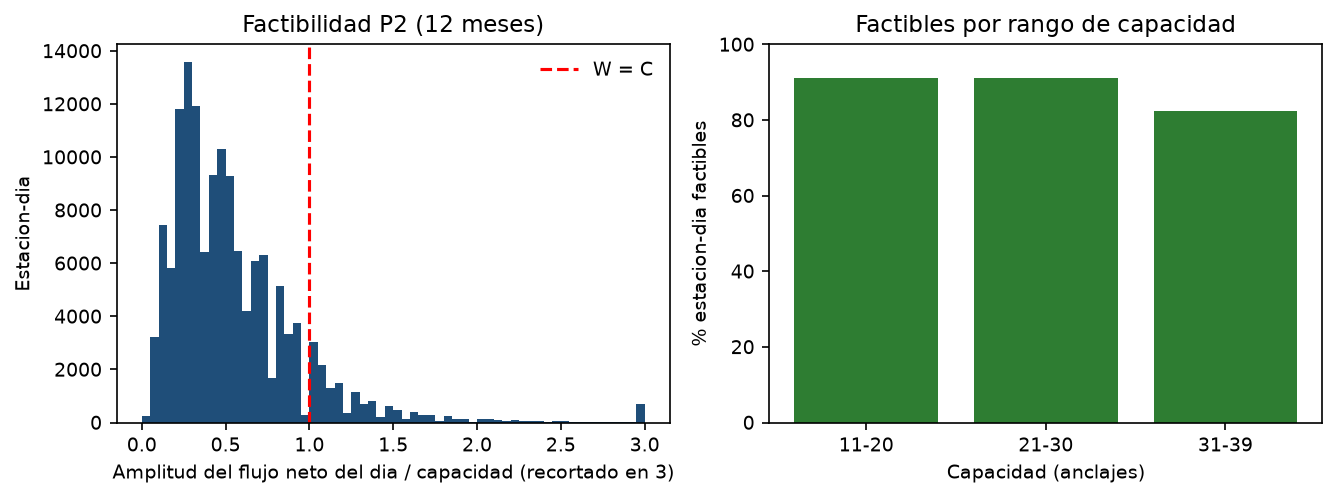

In [8]:
display(Image(filename=str(FIGURES_DIR / "factibilidad_p2.png"), width=900))

## 6. Hallazgos clave para el planteamiento

- **P1 (demanda por estación-hora):** conteos muy sobredispersados. La varianza es 5.48 y la media 1.09
  (índice de dispersión 5.03). El 62.29% de las celdas estación-hora son cero. Poisson se usa como función de
  pérdida para la media, pero para intervalos se evaluará binomial negativa.
- **P2 (riesgo de estación vacía o llena):** en 12 meses, 90.93% de las estación-días son factibles con
  viajes únicamente. En sep-2026 (conjunto de prueba) el porcentaje es 92.33%. Los días no factibles no se
  pueden etiquetar solo con viajes y se excluyen del entrenamiento.
- **P3 (perfiles de estación):** la capacidad mediana es 15 anclajes (rango 0 a 39). Cuatro estaciones tienen
  capacidad 0 y ningún viaje.
- **Calidad:** 758 duplicados exactos (todos en sep-2026), 3,791 viajes con duración no positiva, 295,263
  viajes con origen igual a destino (6.56%) y 32,982 con género nulo o vacío.

## 7. Limitaciones

- Solo viajes: no hay inventario por estación ni eventos de rebalanceo. La factibilidad de P2 es una cota,
  no una medición.
- La capacidad se toma del catálogo de sep-2026 y se aplica a todos los meses.
- El flujo se agrega por hora, así que se pierde el orden dentro de cada hora.
- Aún no hay clima, eventos ni festivos; se agregarán como features.